In [1]:
%pip install scikit-learn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try 'pacman -S
    python-xyz', where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Arch-packaged Python package,
    create a virtual environment using 'python -m venv path/to/venv'.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip.
    
    If you wish to install a non-Arch packaged Python application,
    it may be easiest to use 'pipx install xyz', which will manage a
    virtual environment for you. Make sure you have python-pipx
    installed via pacman.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# 1. Imports and global constants
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC

# Fixed seed so that all results are reproducible
RANDOM_STATE = 42

# Path to the features file generated by preprocessing.ipynb
DATASET_PATH = 'STEW_features.csv'

# Feature subset sizes to compare (the smallest ones go to the quantum SVM)
CANDIDATE_KS = [5, 10, 20, 50, 100]

In [3]:
# 2. Data loading and sanity checks
assert os.path.exists(DATASET_PATH), f"{DATASET_PATH} not found"
data = pd.read_csv(DATASET_PATH)

# Separate features, target and subject ids.
# subject_id is NOT a feature, but we keep it as `groups` so that the
# cross-validation never puts the same person in both train and test.
X = data.drop(columns=['sample_id', 'subject_id', 'label'])
y = data['label']
groups = data['subject_id']

# Make sure the data is clean before any modelling
assert X.isna().sum().sum() == 0, "NaN values found in features"
assert all(np.issubdtype(t, np.number) for t in X.dtypes), "Non-numeric columns found"

print(f"Features matrix: {X.shape}")
print(f"Subjects: {groups.nunique()}")
print(f"Class distribution: {y.value_counts().to_dict()}")

# Keep only the k values that are possible with the available number of features
num_features_list = [k for k in CANDIDATE_KS if k <= X.shape[1]]
print(f"k values to test: {num_features_list}")

Features matrix: (28512, 238)
Subjects: 48
Class distribution: {1: 14256, 0: 14256}
k values to test: [5, 10, 20, 50, 100]


In [4]:
# 3. Shared experimental setup (same for ANOVA and PCA)
# Grouped, stratified CV: no subject appears in both train and validation folds.
# The same object is used for both methods, so they see identical splits.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Same SVM hyperparameter grid for both methods, so any difference in score
# comes from the reduction method and not from different SVM settings.
svm_grid = {
    #'classifier__C': [0.1, 1, 10, 100],
    #'classifier__gamma': ['scale', 0.01, 0.1],
}

# Main metric used to compare the methods
SCORING = 'f1_weighted'

In [5]:
# 4. ANOVA feature selection (SelectKBest) + SVM
# Scaler and selector are inside the Pipeline, so they are fitted
# only on the training fold (no information leaks from validation data).
anova_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('anova', SelectKBest(score_func=f_classif)),
    ('classifier', SVC(kernel='rbf'))
])

# Search over k (number of selected features) and SVM hyperparameters together
anova_param_grid = {'anova__k': num_features_list, **svm_grid}

print("Executing GridSearchCV for ANOVA Feature Selection...")
anova_search = GridSearchCV(
    estimator=anova_pipeline,
    param_grid=anova_param_grid,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1,
    verbose=1
)
# `groups` is required by StratifiedGroupKFold
anova_search.fit(X, y, groups=groups)

print(f"\nANOVA Best k: {anova_search.best_params_['anova__k']}")
print(f"ANOVA Best CV Score (F1-weighted): {anova_search.best_score_:.4f}")

Executing GridSearchCV for ANOVA Feature Selection...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

ANOVA Best k: 50
ANOVA Best CV Score (F1-weighted): 0.7471


In [6]:
# 5. PCA dimensionality reduction + SVM
# StandardScaler before PCA is essential: otherwise features with a large
# scale would dominate the principal components.
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(random_state=RANDOM_STATE)),
    ('classifier', SVC(kernel='rbf'))
])

# Same structure as for ANOVA: k (n_components) + the shared SVM grid
pca_param_grid = {'pca__n_components': num_features_list, **svm_grid}

print("Executing GridSearchCV for PCA Dimensionality Reduction...")
pca_search = GridSearchCV(
    estimator=pca_pipeline,
    param_grid=pca_param_grid,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1,
    verbose=1
)
pca_search.fit(X, y, groups=groups)

print(f"\nPCA Best n_components: {pca_search.best_params_['pca__n_components']}")
print(f"PCA Best CV Score (F1-weighted): {pca_search.best_score_:.4f}")

Executing GridSearchCV for PCA Dimensionality Reduction...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

PCA Best n_components: 100
PCA Best CV Score (F1-weighted): 0.7348


In [7]:
# 6. Results table: best score for every k
anova_res = pd.DataFrame(anova_search.cv_results_)
pca_res = pd.DataFrame(pca_search.cv_results_)

# cv_results_ has one row per (k, C, gamma) combination.
# For each k keep the row with the best mean score (with its std and params).
anova_best = (anova_res.loc[anova_res.groupby('param_anova__k')['mean_test_score'].idxmax()]
                       .sort_values('param_anova__k'))
pca_best = (pca_res.loc[pca_res.groupby('param_pca__n_components')['mean_test_score'].idxmax()]
                    .sort_values('param_pca__n_components'))

ks = anova_best['param_anova__k'].astype(int).values

comparison = pd.DataFrame({
    'k': ks,
    'ANOVA_f1': anova_best['mean_test_score'].values,
    'ANOVA_std': anova_best['std_test_score'].values,
    'PCA_f1': pca_best['mean_test_score'].values,
    'PCA_std': pca_best['std_test_score'].values,
})
print(comparison.round(4).to_string(index=False))

# Saved so teammates can reuse the numbers in the merged notebook
comparison.to_csv('anova_vs_pca_f1.csv', index=False)

  k  ANOVA_f1  ANOVA_std  PCA_f1  PCA_std
  5    0.6465     0.0202  0.6209   0.0350
 10    0.6911     0.0209  0.6815   0.0208
 20    0.7033     0.0345  0.6992   0.0363
 50    0.7471     0.0422  0.7126   0.0512
100    0.7458     0.0433  0.7348   0.0466


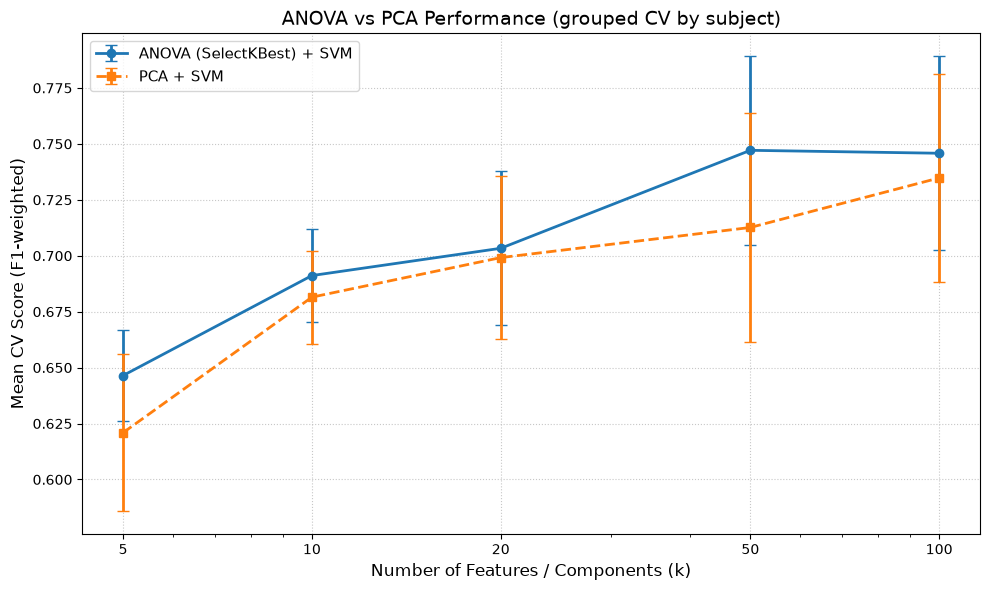

In [8]:
# 7. Performance comparison plot
plt.figure(figsize=(10, 6))

# Error bars = standard deviation across CV folds.
# If they overlap, the two methods should be described as comparable.
plt.errorbar(ks, comparison['ANOVA_f1'], yerr=comparison['ANOVA_std'],
             marker='o', linewidth=2, capsize=4, label='ANOVA (SelectKBest) + SVM')
plt.errorbar(ks, comparison['PCA_f1'], yerr=comparison['PCA_std'],
             marker='s', linewidth=2, linestyle='--', capsize=4, label='PCA + SVM')

# Log scale spreads 5, 10, 20, 50, 100 more evenly
plt.xscale('log')
plt.xticks(ks, ks)

plt.xlabel('Number of Features / Components (k)', fontsize=12)
plt.ylabel('Mean CV Score (F1-weighted)', fontsize=12)
plt.title('ANOVA vs PCA Performance (grouped CV by subject)', fontsize=14)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()

plt.savefig('anova_vs_pca.png', dpi=200)  # must be called before plt.show()
plt.show()

In [9]:
# 8. Extra information for the report
# Best hyperparameters for each k (small k are the ones used for the quantum SVM)
print("ANOVA best configurations:")
print(anova_best[['param_anova__k', 'mean_test_score', 'std_test_score', 'params']].to_string(index=False))
print("\nPCA best configurations:")
print(pca_best[['param_pca__n_components', 'mean_test_score', 'std_test_score', 'params']].to_string(index=False))

# Cumulative explained variance of PCA.
# Fitted on all data: purely descriptive, NOT used for scoring.
Xs = StandardScaler().fit_transform(X)
evr = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Xs).explained_variance_ratio_)
print("\nCumulative explained variance:")
for k in num_features_list:
    print(f"k={k}: {evr[k-1]:.1%}")

ANOVA best configurations:
 param_anova__k  mean_test_score  std_test_score            params
              5         0.646468        0.020229   {'anova__k': 5}
             10         0.691149        0.020853  {'anova__k': 10}
             20         0.703339        0.034476  {'anova__k': 20}
             50         0.747133        0.042214  {'anova__k': 50}
            100         0.745820        0.043268 {'anova__k': 100}

PCA best configurations:
 param_pca__n_components  mean_test_score  std_test_score                     params
                       5         0.620921        0.035036   {'pca__n_components': 5}
                      10         0.681493        0.020825  {'pca__n_components': 10}
                      20         0.699177        0.036330  {'pca__n_components': 20}
                      50         0.712648        0.051156  {'pca__n_components': 50}
                     100         0.734792        0.046635 {'pca__n_components': 100}

Cumulative explained variance:
k=5

In [10]:
# 9. Export the top ANOVA features for the quantum SVM
# Here we only need the list of selected columns, so fitting on all data is fine.
# Report performance from the CV above, not from this fit.
Xs_df = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

for k in [k for k in [5, 10] if k <= X.shape[1]]:
    selector = SelectKBest(f_classif, k=k).fit(Xs_df, y)
    selected_cols = list(X.columns[selector.get_support()])

    # Raw (unscaled) selected features + metadata. The quantum part can apply
    # its own scaling (e.g. MinMaxScaler to [0, pi]).
    data[['sample_id', 'subject_id', 'label'] + selected_cols].to_csv(
        f'anova_top{k}.csv', index=False)
    print(f"ANOVA top-{k}: {selected_cols}")

ANOVA top-5: ['O2_alpha_relative_power', 'T8_delta_relative_power', 'T8_beta_relative_power', 'FC6_alpha_relative_power', 'FC6_beta_relative_power']
ANOVA top-10: ['AF3_theta_relative_power', 'O2_theta_relative_power', 'O2_alpha_relative_power', 'T8_delta_relative_power', 'T8_beta_relative_power', 'FC6_delta_relative_power', 'FC6_alpha_relative_power', 'FC6_beta_relative_power', 'F8_alpha_relative_power', 'F8_beta_relative_power']
